# PRCP-1006: Home Loan Default - Risk Management

**Domain:** Banking

## Problem Statement
A bank wants to know which customers are likely to default on a home loan.
Target: `1` = Defaulter, `0` = Not Defaulter.

## Tasks
1. **Task 1:** Complete data analysis report on the given data
2. **Task 2:** Predictive model to find the factors / customer segments eligible for a loan
3. **Model Comparison Report:** compare multiple models and suggest the best one for production
4. **Challenges Report:** challenges faced on the data, techniques used, and reasons

## Data Files
application_train, bureau, bureau_balance, POS_CASH_balance, credit_card_balance, previous_application, installments_payments

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)
warnings.filterwarnings("ignore")

# 1. Data Loading and First Look

We load the main file `application_train.csv` and check its size, the share of defaulters vs non-defaulters, and the columns with missing values.

In [2]:
# Loading the main file
app = pd.read_csv("data/application_train.csv")
print(app.shape)
app.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# % of defaulters (1) vs non-defaulters (0)
print(app["TARGET"].value_counts(normalize=True) * 100)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [4]:
# Top 10 columns with missing values
print(app.isnull().sum().sort_values(ascending=False).head(10))

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
dtype: int64


# 2. Exploratory Data Analysis (Main Table)

We explore `application_train` to see data types, how the numbers are spread, and which customer groups default more.

In [5]:
app.info()
app.describe()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


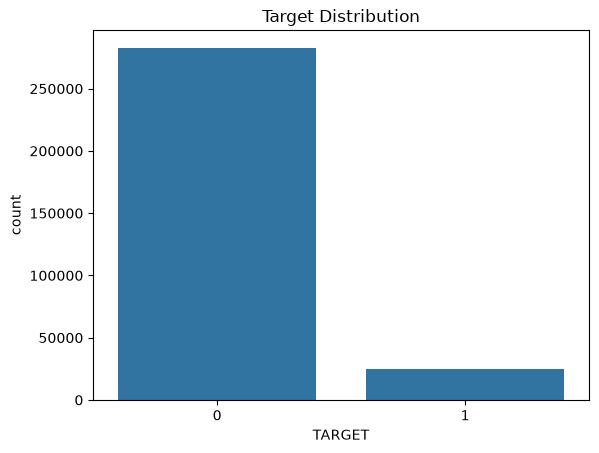

In [6]:
sns.countplot(x = "TARGET", data = app)
plt.title("Target Distribution")
plt.show()

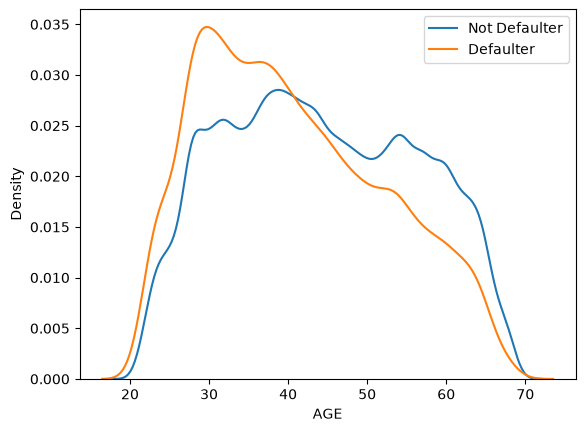

In [7]:
# Age in years (DAYS_BIRTH is negative days)
app["AGE"] = -app["DAYS_BIRTH"] / 365

# Age spread for defaulters vs non-defaulters
sns.kdeplot(app[app["TARGET"] == 0]["AGE"], label = "Not Defaulter")
sns.kdeplot(app[app["TARGET"] == 1]["AGE"], label = "Defaulter")
plt.legend()
plt.show()

In [8]:
# Default rate for each category in a few text columns
cols = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]

for col in cols:
    print(app.groupby(col)["TARGET"].mean().sort_values(ascending = False) * 100)

NAME_CONTRACT_TYPE
Cash loans         8.345913
Revolving loans    5.478329
Name: TARGET, dtype: float64
CODE_GENDER
M      10.141920
F       6.999328
XNA     0.000000
Name: TARGET, dtype: float64
NAME_EDUCATION_TYPE
Lower secondary                  10.927673
Secondary / secondary special     8.939929
Incomplete higher                 8.484966
Higher education                  5.355115
Academic degree                   1.829268
Name: TARGET, dtype: float64
NAME_INCOME_TYPE
Maternity leave         40.000000
Unemployed              36.363636
Working                  9.588472
Commercial associate     7.484257
State servant            5.754965
Pensioner                5.386366
Businessman              0.000000
Student                  0.000000
Name: TARGET, dtype: float64


In [9]:
# Numeric columns most linked to TARGET
corr = app.corr(numeric_only = True)["TARGET"].sort_values()
print(corr.head(10))
print(corr.tail(10))

EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
AGE                          -0.078239
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
AMT_GOODS_PRICE              -0.039645
REGION_POPULATION_RELATIVE   -0.037227
Name: TARGET, dtype: float64
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64


# 3. Understanding the Other Tables

The 6 other files hold the customer's past credit history. We load each one and check its size, columns, and the ID column that links it to the main table.

In [10]:
# Loading all 6 side tables
bureau = pd.read_csv("data/bureau.csv")
bureau_bal = pd.read_csv("data/bureau_balance.csv")
pos = pd.read_csv("data/POS_CASH_balance.csv")
cc = pd.read_csv("data/credit_card_balance.csv")
prev = pd.read_csv("data/previous_application.csv")
inst = pd.read_csv("data/installments_payments.csv")

In [11]:
# size of each table
tables = {"bureau": bureau, "bureau_balance": bureau_bal, "POS_CASH": pos, "credit_card": cc, "previous_app": prev, "installments": inst}

for name, df in tables.items():
    print(name, df.shape)

bureau (1716428, 17)
bureau_balance (27299925, 3)
POS_CASH (10001358, 8)
credit_card (3840312, 23)
previous_app (1670214, 37)
installments (13605401, 8)


In [12]:
for name, df in tables.items():
    print(name)
    print(list(df.columns))
    print()

bureau
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

bureau_balance
['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

POS_CASH
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF']

credit_card
['SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT', 'AMT_DRAWINGS_OTHER_CURRENT', 'AMT_DRAWINGS_POS_CURRENT', 'AMT_INST_MIN_REGULARITY', 'AMT_PAYMENT_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'AMT_RECEIVABLE_PRINCIPAL', 'AMT_RECIVABLE', 'AMT_TOTAL_RECEIVABLE', 'CNT_DRAWINGS_ATM_CURRENT', 'CNT_DRAWINGS_CURRENT', 'CNT_DRAWINGS_OTHER_CURRENT', 'CN

In [13]:
# customers appear in each table
for name, df in tables.items():
    if "SK_ID_CURR" in df.columns:
        print(name, df["SK_ID_CURR"].nunique())

bureau 305811
POS_CASH 337252
credit_card 103558
previous_app 338857
installments 339587


## Observations

- Data is imbalanced: about 8% defaulters vs 92% non-defaulters, so accuracy is not a good metric. We will use ROC-AUC and recall.
- Many building-related columns are missing for about 70% of customers.
- Default is higher for cash loans, men, lower education levels, and younger customers.
- `EXT_SOURCE_1/2/3` are the strongest numeric signals of default.
- `DAYS_EMPLOYED` has a wrong value (365243) that must be cleaned.
- Side tables have many rows per customer, so they must be summarized to one row per customer before merging.

# 4. Summarizing and Merging the Tables

Each side table has many rows per customer. We summarize every table to one row per customer (counts, sums, averages, late payments) and then merge them all into the main table using `SK_ID_CURR`.

In [14]:
# bureau_balance: count months and late months for each past credit 
bureau_bal["LATE"] = bureau_bal["STATUS"].isin(["1", "2", "3", "4","5"]).astype(int)

bb =bureau_bal.groupby("SK_ID_BUREAU").agg(
    BB_MONTHS = ("MONTHS_BALANCE", "count"),
    BB_LATE = ("LATE", "sum")).reset_index()

# Attaching it to bureau(links through SK_ID_BUREAU)
bureau = bureau.merge(bb, on = "SK_ID_BUREAU", how = "left")

In [15]:
# bureau: one row per customer
bur = bureau.groupby("SK_ID_CURR").agg(
    BUR_COUNT = ("SK_ID_BUREAU", "count"),
    BUR_CREDIT_SUM = ("AMT_CREDIT_SUM", "sum"),
    BUR_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUR_OVERDUE_SUM=("AMT_CREDIT_SUM_OVERDUE", "sum"),
    BUR_LATE_MONTHS=("BB_LATE", "sum")).reset_index()

In [16]:
# previous_application: how many times applied and how many were refused
prev["REFUSED"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(int)

pa = prev.groupby("SK_ID_CURR").agg(
    PREV_COUNT = ("SK_ID_PREV", "count"),
    PREV_REFUSED = ("REFUSED", "sum"),
    PREV_CREDIT_MEAN = ("AMT_CREDIT", "mean")).reset_index()

In [17]:
# POS_CASH: days past due(DPD)
p = pos.groupby("SK_ID_CURR").agg(
    POS_COUNT = ("SK_ID_PREV", "count"),
    POS_DPD_MAX = ("SK_DPD", "max"),
    POS_DPD_MEAN = ("SK_DPD", "mean")).reset_index()

In [18]:
# credit_card: balance, limit and days past due
c = cc.groupby("SK_ID_CURR").agg(
    CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
    CC_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_DPD_MAX=("SK_DPD", "max")).reset_index()

In [19]:
# installments: paid late (positive = late) and paid less than due
inst["DAYS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
inst["UNDERPAID"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]

i = inst.groupby("SK_ID_CURR").agg(
    INST_COUNT=("SK_ID_PREV", "count"),
    INST_LATE_MEAN=("DAYS_LATE", "mean"),
    INST_UNDERPAID_SUM=("UNDERPAID", "sum")).reset_index()

In [20]:
# Merge everything into the main table (left join keeps all 307,511 customers)
df = app.copy()

for table in [bur, pa, p, c, i]:
    df = df.merge(table, on="SK_ID_CURR", how="left")

print(df.shape)

(307511, 140)


In [21]:
# Correlation of the new columns with TARGET
new_cols = [col for col in df.columns if col.startswith(("BUR_", "PREV_", "POS_", "CC_", "INST_"))]
print(df[new_cols + ["TARGET"]].corr()["TARGET"].sort_values())

POS_COUNT            -0.035632
INST_COUNT           -0.021096
PREV_CREDIT_MEAN     -0.016114
BUR_CREDIT_SUM       -0.014057
CC_LIMIT_MEAN        -0.008852
CC_DPD_MAX           -0.005975
BUR_COUNT             0.004056
POS_DPD_MAX           0.004763
POS_DPD_MEAN          0.005436
BUR_DEBT_SUM          0.007144
BUR_OVERDUE_SUM       0.013335
BUR_LATE_MONTHS       0.017204
PREV_COUNT            0.019762
INST_LATE_MEAN        0.020870
INST_UNDERPAID_SUM    0.027326
PREV_REFUSED          0.064469
CC_BALANCE_MEAN       0.087177
TARGET                1.000000
Name: TARGET, dtype: float64


## Observations

- After merging, the data has 307,511 rows and 140 columns, so no customers were lost.
- The new history columns have weak correlation with default (strongest: `CC_BALANCE_MEAN` 0.087, `PREV_REFUSED` 0.064).
- High credit card balance and earlier refused applications go with higher default.
- A longer repayment history goes with lower default.

# 5. Data Cleaning

We fix the wrong `DAYS_EMPLOYED` value, fill the history columns for customers with no past records, drop columns with too many missing values, and convert text columns to numbers.

In [22]:
# 365243 is fake number for "not working". Marking those people, then blank it out
df["NOT_EMPLOYED"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
print(df["DAYS_EMPLOYED"].describe())

count    252137.000000
mean      -2384.169325
std        2338.360162
min      -17912.000000
25%       -3175.000000
50%       -1648.000000
75%        -767.000000
max           0.000000
Name: DAYS_EMPLOYED, dtype: float64


In [23]:
# No record means the person never took that product, so put 0
df[new_cols] = df[new_cols].fillna(0)

In [24]:
# Remove columns that are mostly empty (more than 60%)
missing_pct = df.isnull().mean()
drop_cols = missing_pct[missing_pct > 0.6].index
df = df.drop(columns=drop_cols)
print(len(drop_cols), "columns dropped")

17 columns dropped


In [25]:
# A few people have a huge income, so cut it at a limit
df["AMT_INCOME_TOTAL"] = df["AMT_INCOME_TOTAL"].clip(upper=df["AMT_INCOME_TOTAL"].quantile(0.999))

In [26]:
# Models only understand numbers, so change text columns to numbers
text_cols = df.select_dtypes(exclude="number").columns

for col in text_cols:
    df[col] = LabelEncoder().fit_transform(df[col].fillna("Unknown").astype(str))

print(df.shape)

(307511, 124)


## Observations

- Fixed `DAYS_EMPLOYED`: about 55,000 customers had the fake value 365243, now marked in `NOT_EMPLOYED`.
- Removed 17 columns that were more than 60% empty.
- All text columns are now numbers, and the data has 307,511 rows and 124 columns.

# 6. Feature Engineering

Creating new columns from the existing ones, like loan vs income and the average of the three `EXT_SOURCE` scores. These ratios often tell more about a customer's risk than the raw amounts.

In [27]:
# Comparing loan size and yearly payment with the customer's income
df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]

# Checked how long the loan will run (credit divided by yearly payment)
df["CREDIT_TERM"] = df["AMT_CREDIT"] /df["AMT_ANNUITY"]

In [28]:
# Checked how much of life the customer has been employed, and income per family member
df["EMPLOYED_AGE_RATIO"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"]

In [29]:
# The average and minimum of the 3 external scores (ignores empty ones)
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
df["EXT_MEAN"] = df[ext_cols].mean(axis=1)
df["EXT_MIN"] = df[ext_cols].min(axis=1)

In [30]:
# Checked how strongly the new columns link to TARGET
new_feats = ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM",
             "EMPLOYED_AGE_RATIO", "INCOME_PER_PERSON", "EXT_MEAN", "EXT_MIN"]
print(df[new_feats + ["TARGET"]].corr()["TARGET"].sort_values())
print(df.shape)

EXT_MEAN               -0.222052
EXT_MIN                -0.185266
EMPLOYED_AGE_RATIO     -0.067955
CREDIT_TERM            -0.032102
INCOME_PER_PERSON      -0.015310
CREDIT_INCOME_RATIO    -0.007745
ANNUITY_INCOME_RATIO    0.014239
TARGET                  1.000000
Name: TARGET, dtype: float64
(307511, 131)


## Observations

- `EXT_MEAN` (-0.222) is stronger than any single `EXT_SOURCE` column, so combining them helped.
- `EMPLOYED_AGE_RATIO` links to default more than the raw `DAYS_EMPLOYED`.
- The loan-to-income ratios are weak on their own, but I keep them for the tree models.
- The data now has 131 columns.

# 7. Train-Test Split and Imbalance

Split the data into 80% training and 20% testing, fill the remaining empty values, and check how imbalanced the target is. For the imbalance, I will give defaulters extra weight in the models instead of copying or deleting rows.

In [31]:
# Separating the input columns (X) from the answer column (y)
X = df.drop(columns = ["TARGET", "SK_ID_CURR"])
y = df["TARGET"]

# Divisions can create infinite values, so making them empty
X = X.replace([np.inf, -np.inf], np.nan)

In [32]:
# Keeping 20% for testing with the same defaulter share in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state = 42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(246008, 129) (61503, 129)
0.08072908198107379 0.08072776937710356


In [33]:
# Filling empty values with the median, learned from the training data only 
imputer = SimpleImputer(strategy = "median")

X_train = pd.DataFrame(imputer.fit_transform(X_train), columns = X.columns, index = X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns = X.columns, index = X_test.index)

print(X_train.isnull().sum().sum())

0


In [34]:
# Find how many non-defaulters there are for each defaulter
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(ratio)

11.38710976837865


## Observations
- Split the data 80/20 and the defaulter share is 8.07% in both train and test.
- Filled empty values using the median from the training data only.
- There are about 11.4 non-defaulters for each defaulter, so I will give defaulters extra weight in the models.

# 8. Model Training

Train 3 models: Logistic Regression as a simple baseline, Random Forest, and LightGBM. In each model I give defaulters extra weight because of the imbalance, and I check ROC-AUC on the test data.

In [35]:
# Logistic Regression needs numbers on the same scale
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Baseline model, "balanced" gives defaulter extra weight
lr = LogisticRegression(class_weight = "balanced", max_iter = 1000)
lr.fit(X_train_s, y_train)

lr_prob = lr.predict_proba(X_test_s)[:, 1]
print("Logistic Regression AUC:", roc_auc_score(y_test, lr_prob))

Logistic Regression AUC: 0.7548085849237848


In [36]:
# Random Forest, limit the depth so it trains faster and doesn't overfit
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=50,
                            class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

rf_prob = rf.predict_proba(X_test)[:, 1]
print("Random Forest AUC:", roc_auc_score(y_test, rf_prob))

Random Forest AUC: 0.7522089306243139


In [37]:
# LightGBM, using the ratio (11.4) as extra weight for defaulters
lgb = LGBMClassifier(n_estimators=300, learning_rate=0.05, scale_pos_weight=ratio,
                     random_state=42, verbose=-1)
lgb.fit(X_train, y_train)

lgb_prob = lgb.predict_proba(X_test)[:, 1]
print("LightGBM AUC:", roc_auc_score(y_test, lgb_prob))

LightGBM AUC: 0.779650425025837


## Observations
- LightGBM has the best AUC (0.780), then Logistic Regression (0.755) and Random Forest (0.752).
- I used class weights in all three models to handle the imbalance.
- AUC alone is not enough here, so I will also check precision, recall and F1 in the next step.

# 9. Model Comparison

Compared the three models using AUC, precision, recall and F1 on the test data, plot their ROC curves, and look at the confusion matrix of the best model. Then I choose the model for production.

In [38]:
# Results of all models in one table (threshold 0.5)
models = {"Logistic Regression": lr_prob, "Random Forest": rf_prob, "LightGBM": lgb_prob}
rows = []

for name, prob in models.items():
    pred = (prob >= 0.5).astype(int)
    rows.append({"Model": name,
                 "AUC": roc_auc_score(y_test, prob),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).round(3)
print(results)

                 Model    AUC  Precision  Recall     F1
0  Logistic Regression  0.755      0.165   0.680  0.266
1        Random Forest  0.752      0.169   0.659  0.270
2             LightGBM  0.780      0.184   0.693  0.291


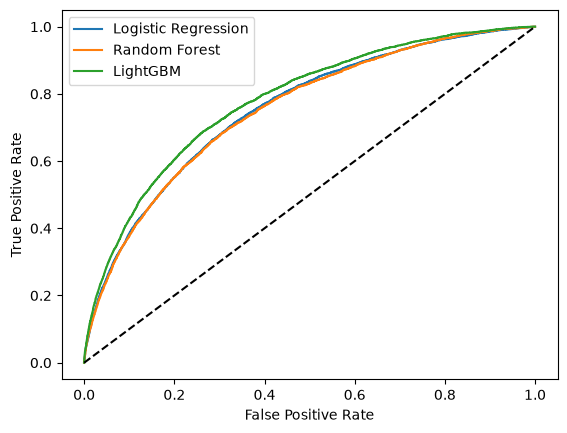

In [39]:
# the ROC curve of each model, the dotted line is random guessing
for name, prob in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

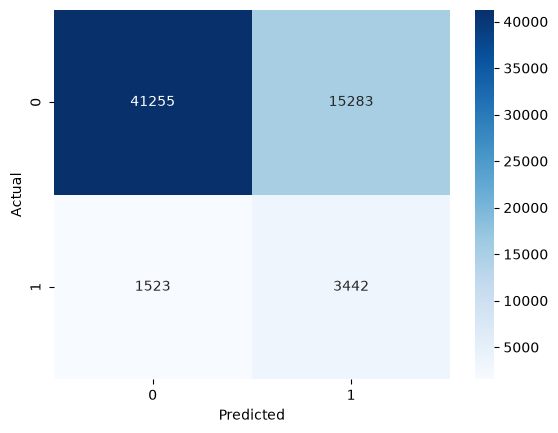

              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.18      0.69      0.29      4965

    accuracy                           0.73     61503
   macro avg       0.57      0.71      0.56     61503
weighted avg       0.90      0.73      0.79     61503



In [40]:
# look at the confusion matrix of LightGBM
lgb_pred = (lgb_prob >= 0.5).astype(int)
sns.heatmap(confusion_matrix(y_test, lgb_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, lgb_pred))

## Observations 

- LightGBM is the best model: AUC 0.780, recall 0.693, F1 0.291. Logistic Regression and Random Forest are very close to each other.
- LightGBM catches 3,442 of 4,965 defaulters (69%) but also flags 15,283 good customers, so precision is low (0.18).
- Accuracy (73%) is not a good measure here because of the 92/8 imbalance.
- I choose LightGBM for production. The bank can change the cut-off to balance missed defaulters against rejected good customers.

# 10. Important Factors and Customer Segments

Checking which columns LightGBM uses the most to find the factors behind default. Then I split customers into 5 risk groups using the predicted probability and check the real default rate in each group.

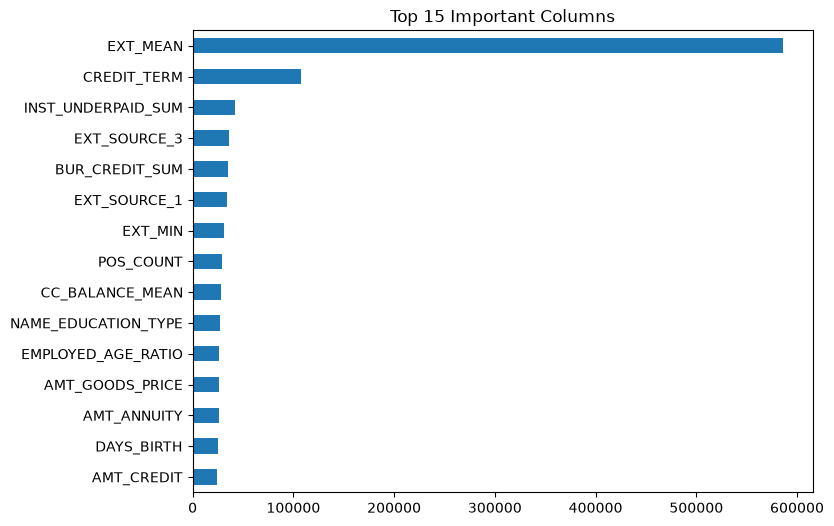

In [41]:
# Importance of each column (gain = how much it improves the model)
imp = pd.Series(lgb.booster_.feature_importance(importance_type="gain"), index=X.columns)
imp = imp.sort_values(ascending=False).head(15)

# I plot the top 15 columns
imp.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 Important Columns")
plt.show()

In [42]:
# Test customers into 5 equal risk groups using the predicted probability
risk = pd.DataFrame({"prob": lgb_prob, "actual": y_test.values})
risk["group"] = pd.qcut(risk["prob"], 5, labels=["Very Low", "Low", "Medium", "High", "Very High"])

# I check the real default rate in each group
print(risk.groupby("group")["actual"].mean() * 100)

group
Very Low      1.300707
Low           2.991870
Medium        4.763840
High          8.772358
Very High    22.534753
Name: actual, dtype: float64


## Observations

- `EXT_MEAN` is by far the most important column, followed by `CREDIT_TERM`. Both are columns I created.
- Columns from the side tables (`INST_UNDERPAID_SUM`, `BUR_CREDIT_SUM`, `POS_COUNT`, `CC_BALANCE_MEAN`) are in the top 15, so past credit history helps the model.
- Real default rate rises from 1.3% in the Very Low group to 22.5% in the Very High group, against an average of 8%.
- Risky customers: low external scores, long loan term, underpaid installments, younger age, lower education.

# The two reports

# 11. Model Comparison Report

I trained three models on 80% of the data and tested them on the remaining 20% (61,503 customers). I used class weights in all of them because only 8% of customers are defaulters.

| Model | AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression | 0.755 | 0.165 | 0.680 | 0.266 |
| Random Forest | 0.752 | 0.169 | 0.659 | 0.270 |
| LightGBM | 0.780 | 0.184 | 0.693 | 0.291 |

## Best model for production: LightGBM

- It has the best AUC, precision, recall and F1.
- It catches 69% of defaulters (3,442 out of 4,965) on the test data.
- It separates customers into risk groups well: real default rate goes from 1.3% (Very Low) to 22.5% (Very High).
- The bank can use these risk groups for risk management: approve Very Low and Low customers easily, review Medium and High ones, and set stricter limits or higher rates for Very High ones.
- It handles missing values and mixed data well, and it trains fast.

## Limits
- Precision is low (0.18), so many good customers are flagged as risky. The bank should set the cut-off based on the cost of a missed defaulter against a rejected good customer.
- I used default settings and did not tune the models, so the result can still be improved.

# Report on Challenges Faced

| Challenge | What I did | Why |
|---|---|---|
| Only 8% defaulters | Used class weights and checked AUC and recall, not accuracy | Accuracy would be 92% even if no defaulter is caught |
| 7 tables with many rows per customer | Summarized each table to one row per customer and merged | A model needs one row per customer |
| Wrong value 365243 in `DAYS_EMPLOYED` | Replaced it with empty and added a `NOT_EMPLOYED` flag | The number is fake, but "not employed" is useful |
| Many empty values | Dropped columns over 60% empty, filled history with 0, filled the rest with median | No history means no past product |
| Data leakage risk | Filled empty values after the train-test split | Test data should not affect training |